# Data management, transforms and masks

Load tables and arrays, select and rebin a region, convert genomic tracks, and apply the same data and region transforms used by the Data Manager. All main examples run offline with bundled or synthetic inputs.

Run cells in order with DNAscape installed in the selected kernel. Exports go to `examples/outputs/data_management/`. Public BigWig examples at the end are opt-in.

1. Inputs and data shapes
2. Region selection and resolution
3. Formats and coordinate-aware conversion
4. Genomic tracks and Repli-seq fractions
5. Data transforms and region transforms
6. Optional public BigWig import


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "data_management"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import rload, rsave, rdata, rtrack, select_profile_region
from dnascape.workflows import (
    DataConversionRequest,
    DataFilterSettings,
    FilterProfile,
    ProfileModulationSettings,
    convert_data,
    convert_combined_data,
    evaluate_formula,
    apply_data_filter,
)
from dnascape.workflows.uploads import inspect_upload
from dnascape.workflows.conversion import filter_positions_artifact

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\data_management


## 1. Inputs and data shapes

Use `rload` for ready-formatted files. A spatial vector has shape `(n,)`, a time profile `(1, T)`, and a space–time field `(n, T)`. A matrix of conditions has the same shape as a space–time field but becomes chronological data only when its columns represent ordered times. Coordinates and units must be defined separately when plain arrays do not carry them.


In [2]:
TIMING_PATH = PROJECT_DIR / "examples/data/example/replication_timing_hESC.csv"
full_timing = rload(TIMING_PATH, chromosome="chr1", data_form="space")
pd.DataFrame(
    {
        "Dependence": ["Space", "Time", "Space–time"],
        "Example shape": [(6,), (1, 4), (6, 4)],
    }
)


,Dependence,Example shape
0,Space,"(6,)"
1,Time,"(1, 4)"
2,Space–time,"(6, 4)"


## 2. Region selection and resolution

Intervals are half-open: `[start, end)`. Average when increasing the bin width; interpolate when decreasing it. Both operations retain the selected genomic interval. Interpolation creates a finer grid, not additional experimental information.


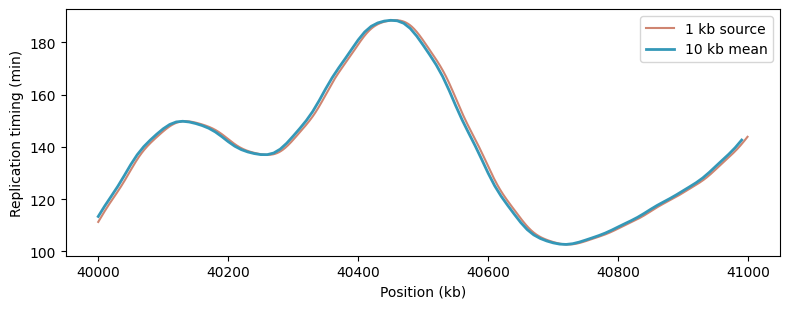

In [3]:
REGION_KB = (40_000.0, 41_000.0)
timing_1kb, positions_1kb = select_profile_region(
    full_timing, interval_kb=REGION_KB, output_resolution_kb=1.0
)
timing_10kb, positions_10kb = select_profile_region(
    full_timing,
    interval_kb=REGION_KB,
    output_resolution_kb=10.0,
    resample_method="mean",
)
timing_fine, positions_fine = select_profile_region(
    full_timing,
    interval_kb=REGION_KB,
    output_resolution_kb=0.5,
    resample_method="linear",
)
assert (timing_1kb.size, timing_10kb.size, timing_fine.size) == (1000, 100, 2000)
fig, ax = plt.subplots()
ax.plot(positions_1kb, timing_1kb, label="1 kb source", alpha=0.6)
ax.plot(positions_10kb, timing_10kb, label="10 kb mean", linewidth=2)
ax.set(xlabel="Position (kb)", ylabel="Replication timing (min)")
ax.legend()
fig.tight_layout()
plt.show()


## 3. Formats and coordinate-aware conversion

`rsave` and `rload` support TSV, TXT, CSV and NPZ. The following round trip exports only values, so retain the region and resolution alongside them. Use a labelled table or `np.savez_compressed` when coordinate metadata must travel with the data.


In [4]:
for suffix in ("tsv", "txt", "csv", "npz"):
    path = OUTPUT_DIR / f"timing_x.{suffix}"
    rsave(timing_10kb, path, data_form="space")
    recovered = np.asarray(rload(path, data_form="space")).reshape(-1)
    np.testing.assert_allclose(recovered, timing_10kb)
print("Round trips passed: TSV, TXT, CSV and NPZ")
coordinate_table = pd.DataFrame(
    {"position_kb": positions_10kb, "timing_min": timing_10kb}
)
rsave(coordinate_table, OUTPUT_DIR / "timing_coordinates.tsv")
coordinate_table.head()

# Convert an existing file without changing its numeric grid.
rdata(
    OUTPUT_DIR / "timing_x.npz",
    target="tsv",
    output_path=OUTPUT_DIR / "timing_converted.tsv",
    data_form="space",
)


Round trips passed: TSV, TXT, CSV and NPZ


WindowsPath('C:/Users/FRANCI~1/AppData/Local/Temp/dnascape-notebooks-xu2jypqh/outputs/data_management/timing_converted.tsv')

### Rebin an uploaded DNAscape profile

The headless workflows share the app's inspection and conversion rules. This example supplies a 1 kb profile, selects a smaller region in **bp**, and exports 10 kb bins. It works without starting the app.


In [5]:
import io

buffer = io.StringIO()
np.savetxt(buffer, timing_1kb)
upload = inspect_upload("timing.txt", buffer.getvalue().encode(), expected_form="x")
request = DataConversionRequest(
    inspection=upload,
    input_form="x",
    output_name="timing_rebinned",
    target_format="npz",
    profile_binning=True,
    source_start=40_000_000,
    source_bin_size=1000,
    start=40_100_000,
    end=40_900_000,
    bin_size=10_000,
    missing_policy="error",
)
converted = convert_data(request)
(OUTPUT_DIR / converted.artifact.filename).write_bytes(converted.artifact.data)
print(f"Converted shape: {converted.shape}; exported {converted.artifact.filename}")
assert converted.shape == (80,)


Converted shape: (80,); exported timing_rebinned.npz


## 4. Genomic tracks and Repli-seq fractions

Genomic track coordinates use **bp**. `rtrack` bins interval signals into arrays or labelled tables. This synthetic bedGraph includes one missing interval to make interpolation visible. Choose aggregation and missing-value handling to match the assay; an enrichment signal is not automatically an absolute initiation rate.


In [6]:
bedgraph = pd.DataFrame(
    {
        "chrom": ["chr1"] * 4,
        "start": [0, 10_000, 30_000, 50_000],
        "end": [10_000, 20_000, 40_000, 60_000],
        "signal": [0.2, 0.6, 0.4, 0.9],
    }
)
track_table = rtrack(
    bedgraph,
    source_format="bedgraph",
    chromosome="chr1",
    start=0,
    end=60_000,
    bin_size=10_000,
    aggregation="mean",
    missing="nan",
    interpolation="linear",
    as_table=True,
    value_name="enrichment",
)
assert len(track_table) == 6
track_table


,chrom,start_bp,end_bp,position_bp,position_kb,enrichment
0,chr1,0,10000,5000.0,5.0,0.20
1,chr1,10000,20000,15000.0,15.0,0.60
2,chr1,20000,30000,25000.0,25.0,0.50
3,chr1,30000,40000,35000.0,35.0,0.40
4,chr1,40000,50000,45000.0,45.0,0.65
5,chr1,50000,60000,55000.0,55.0,0.90


### Aligned fractions or conditions

Multiple aligned tracks produce one matrix. Keep chronological fraction order explicit; arbitrary conditions cannot be interpreted as elapsed time.


In [7]:
late_track = bedgraph.copy()
late_track["signal"] = 1.0 - late_track["signal"]
conditions = rtrack(
    [bedgraph, late_track],
    source_format="bedgraph",
    chromosome="chr1",
    start=0,
    end=60_000,
    bin_size=10_000,
    labels=["early", "late"],
    interpolation="linear",
    data_form="spacetime",
    return_metadata=True,
)
assert conditions["values"].shape == (6, 2)
rsave(conditions["table"], OUTPUT_DIR / "aligned_conditions.tsv")
conditions["table"]


,chrom,start_bp,end_bp,position_bp,position_kb,early,late
0,chr1,0,10000,5000.0,5.0,0.20,0.80
1,chr1,10000,20000,15000.0,15.0,0.60,0.40
2,chr1,20000,30000,25000.0,25.0,0.50,0.50
3,chr1,30000,40000,35000.0,35.0,0.40,0.60
4,chr1,40000,50000,45000.0,45.0,0.65,0.35
5,chr1,50000,60000,55000.0,55.0,0.90,0.10


### Timing from sixteen Repli-seq fractions

For **sixteen equally spaced chronological fractions**, the app supports a signal-weighted mean time or a sigmoid estimate of T50. This synthetic example illustrates both without downloading experimental data. An S-phase duration is needed to express the result in minutes.


In [8]:
from dnascape.workflows.repliseq import replication_timing_from_fractions

fraction_midpoints = (np.arange(16) + 0.5) / 16
centres = np.linspace(0.15, 0.85, 30)
fractions = np.exp(
    -0.5 * ((fraction_midpoints[None, :] - centres[:, None]) / 0.12) ** 2
)
mean_time = replication_timing_from_fractions(
    fractions, method="mean", s_phase_duration_min=600.0
)
t50 = replication_timing_from_fractions(
    fractions, method="sigmoid", s_phase_duration_min=600.0
)
assert np.isfinite(mean_time).all() and np.isfinite(t50).all()
pd.DataFrame(
    {"Bin": np.arange(30), "Weighted mean (min)": mean_time, "Sigmoid T50 (min)": t50}
).head()


,Bin,Weighted mean (min),Sigmoid T50 (min)
0,0,104.562851,101.493812
1,1,115.131784,112.572344
2,2,126.510398,124.457914
3,3,138.616516,137.039338
4,4,151.347388,150.189212


## 5. Data transforms and region transforms

Data transforms evaluate numeric Python/NumPy expressions over the whole source. `source` denotes one input; a combined transform uses `source1`, `source2`, and so on. Available operations include arithmetic, logs, powers, smoothing and convolution. Expressions preserve the array shape and do not execute general Python statements.


In [9]:
source = np.asarray(track_table["enrichment"])
transformed = evaluate_formula("np.log1p(source)", {"source": source})
combined = evaluate_formula(
    "0.7 * source1 + 0.3 * source2", {"source1": source, "source2": transformed}
)
assert combined.shape == source.shape
pd.DataFrame({"Source": source, "log1p(source)": transformed, "Weighted sum": combined})


,Source,log1p(source),Weighted sum
0,0.20,0.182322,0.194696
1,0.60,0.470004,0.561001
2,0.50,0.405465,0.471640
3,0.40,0.336472,0.380942
4,0.65,0.500775,0.605233
5,0.90,0.641854,0.822556


### Combine two prepared sources

The same formula can be passed to the complete conversion workflow, yielding one generated file. Both source arrays must share a meaningful grid.


In [10]:
def array_request(values, name):
    stream = io.StringIO()
    np.savetxt(stream, values)
    return DataConversionRequest(
        inspection=inspect_upload(
            name + ".txt", stream.getvalue().encode(), expected_form="x"
        ),
        input_form="x",
        target_format="npz",
        output_name=name,
        missing_policy="error",
    )


combined_result = convert_combined_data(
    (array_request(source, "source1"), array_request(transformed, "source2")),
    "0.7 * source1 + 0.3 * source2",
    output_name="combined_profile",
)
(OUTPUT_DIR / combined_result.artifact.filename).write_bytes(
    combined_result.artifact.data
)
print(combined_result.artifact.filename, combined_result.shape)


combined_profile.npz (6,)


### Define a mask and transform selected regions

Region transforms act **after preparation**. Define the mask using thresholds, missing values, position ranges, an uploaded profile or the whole region. `complement=True` inverts the mask within that region. The Python settings retain the class name `DataFilterSettings` for compatibility with existing scripts.


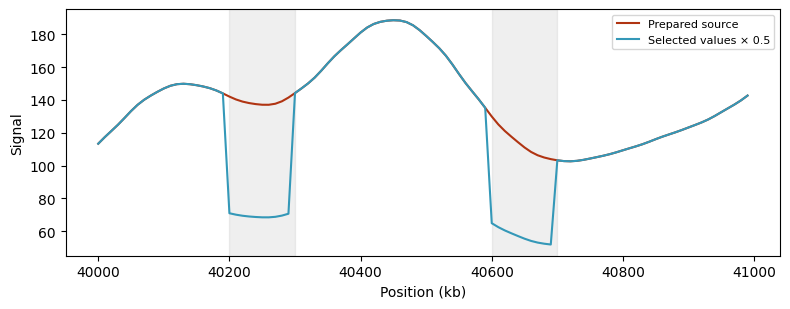

In [11]:
region_settings = DataFilterSettings(
    enabled=True,
    selection="ranges",
    position_ranges="(40200000,40300000), (40600000,40700000)",
    profile_units="bp",
    action="multiply",
    value=0.5,
)
# Coordinates supplied to the headless region-transform API are in kb.
edited = apply_data_filter(timing_10kb, region_settings, positions=positions_10kb)
selected = ((positions_10kb >= 40_200) & (positions_10kb < 40_300)) | (
    (positions_10kb >= 40_600) & (positions_10kb < 40_700)
)
np.testing.assert_allclose(edited[~selected], timing_10kb[~selected])
np.testing.assert_allclose(edited[selected], 0.5 * timing_10kb[selected])
fig, ax = plt.subplots()
ax.plot(positions_10kb, timing_10kb, label="Prepared source")
ax.plot(positions_10kb, edited, label="Selected values × 0.5")
for start, end in [(40_200, 40_300), (40_600, 40_700)]:
    ax.axvspan(start, end, color="grey", alpha=0.12)
ax.set(xlabel="Position (kb)", ylabel="Signal")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Modulate with another profile

Use `source` for the selected signal and `profile` for a prepared covariate, such as gene locations or a ChIP-seq track. Align coordinates and resolution before combining. The expression changes only masked positions; a shorter profile can be aligned from its beginning when explicitly requested.


In [12]:
covariate = np.linspace(0.5, 1.5, timing_10kb.size)
modulation = ProfileModulationSettings(
    operation="expression", values=covariate, expression="source * profile"
)
modulated = apply_data_filter(
    timing_10kb,
    DataFilterSettings(
        enabled=True,
        selection="ranges",
        position_ranges="(40200000,40300000)",
        profile_units="bp",
        action="modulate",
        modulation=modulation,
    ),
    positions=positions_10kb,
)
assert np.isfinite(modulated).all()
pd.DataFrame(
    {"Position (kb)": positions_10kb, "Source": timing_10kb, "Modulated": modulated}
).iloc[18:24]


,Position (kb),Source,Modulated
18,40180.0,145.742686,145.742686
19,40190.0,143.950507,143.950507
20,40200.0,142.002189,99.688405
21,40210.0,140.263176,99.884383
22,40220.0,138.958668,100.359038
23,40230.0,138.062577,101.106433


### Export and reuse the mask

Conversion results retain the applied mask. Export it as a plain integer **bp position list** or half-open intervals, without a chromosome header or value column. Reuse these exports with **Upload profile** in any app page's Region transforms section.


In [13]:
from dataclasses import replace

masked_result = convert_data(
    replace(
        request,
        output_name="masked_timing",
        data_filter=DataFilterSettings(
            enabled=True,
            selection="ranges",
            position_ranges="(40200000,40300000)",
            profile_units="bp",
            action="replace",
            value=0.0,
        ),
    )
)
for layout in ("positions", "intervals"):
    artifact = filter_positions_artifact(
        masked_result, output_name=f"mask_{layout}", layout=layout
    )
    (OUTPUT_DIR / artifact.filename).write_bytes(artifact.data)
    print(artifact.filename, artifact.data.decode().splitlines()[:3])


mask_positions.tsv ['40200000', '40210000', '40220000']
mask_intervals.tsv ['40200000\t40300000']


### Reuse an exported position mask

A position list is one genomic coordinate per line. Load it as a FilterProfile with explicit units; values outside that mask remain unchanged.


In [14]:
position_artifact = filter_positions_artifact(
    masked_result, output_name="reusable_mask"
)
positions_bp = np.loadtxt(io.StringIO(position_artifact.data.decode()), ndmin=1)
reused_mask = DataFilterSettings(
    enabled=True,
    selection="profile",
    action="replace",
    value=0.0,
    profile=FilterProfile(positions_bp, layout="positions", units="bp"),
)
reused_values = apply_data_filter(timing_10kb, reused_mask, positions=positions_10kb)
assert np.all(reused_values[(positions_10kb >= 40200) & (positions_10kb < 40300)] == 0)
print("Exported mask successfully reused")


Exported mask successfully reused


## 6. Optional public BigWig import

Set `RUN_PUBLIC_DOWNLOADS=True` to download two K562 example tracks. The default offline run skips this section. BigWig readers for the **headless Data Manager workflow** match the app: `pybigtools` on Python 3.10–3.13, or `figwig` on Python 3.14 and later. Install with `python -m pip install -e ".[app]"` from the repository root. The core `rtrack` BigWig importer is a separate API that uses the `genomics` extra (`pyBigWig`).

The Repli-seq wave signal is a **relative replication signal**, not an absolute clock. The OK-seq track provides signed fork directionality. Inspect the assay and genome assembly before comparing datasets; scale relative signals only with explicit biological assumptions.


In [15]:
RUN_PUBLIC_DOWNLOADS = False
PUBLIC_TRACKS = {
    "k562_repliseq": "https://hgdownload.gi.ucsc.edu/goldenPath/hg19/encodeDCC/wgEncodeUwRepliSeq/wgEncodeUwRepliSeqK562WaveSignalRep1.bigWig",
    "k562_okseq": "https://raw.githubusercontent.com/CL-CHEN-Lab/OK-Seq/master/published_results/K562/K562_merged_hmm_RFD_cutoff10_bs1kb_sorted.bw",
}
if RUN_PUBLIC_DOWNLOADS:
    import shutil
    from urllib.request import Request, urlopen
    from dnascape.workflows.bigwig import inspect_bigwig, read_bigwig_bins

    for name, url in PUBLIC_TRACKS.items():
        destination = OUTPUT_DIR / (name + ".bigWig")
        if not destination.exists():
            partial = destination.with_suffix(".download")
            try:
                with (
                    urlopen(
                        Request(url, headers={"User-Agent": "DNAscape notebook"}),
                        timeout=60,
                    ) as remote,
                    partial.open("wb") as local,
                ):
                    shutil.copyfileobj(remote, local)
                partial.replace(destination)
            finally:
                partial.unlink(missing_ok=True)
        metadata = inspect_bigwig(destination)
        signal = read_bigwig_bins(
            destination,
            chromosome="chr1",
            start=40_000_000,
            end=41_000_000,
            bin_size=10_000,
            aggregation="mean",
        )
        assert signal.shape == (100,) and np.isfinite(signal).any()
        table = pd.DataFrame(
            {"position_kb": np.arange(40_000.0, 41_000.0, 10.0), name: signal}
        )
        rsave(table, OUTPUT_DIR / (name + "_chr1.tsv"))
        print(name, metadata.backend, signal.shape, "missing:", np.isnan(signal).sum())
else:
    print("Public downloads are off; all offline examples above have run.")


Public downloads are off; all offline examples above have run.


Continue with the [mapping atlas](2-mapping.ipynb). Keep raw uploads unchanged, retain coordinates and units with exports, and distinguish relative assay enrichment from calibrated timing or initiation-rate units. See the [data preparation documentation](https://dnascape.readthedocs.io/en/latest/datamanagement.html) for further options.
